<a href="https://colab.research.google.com/github/kar0karbl/1-TM-Batisova/blob/main/1laba(1)_TM_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


№1. ТЕОРЕТИЧЕСКИЙ РАСЧЁТ
-------------------------------------------------------

1) e(ϕ), исходное: -h*cos(θ - ϕ) + sin(ϕ)**2/2
θ= 0°: e = -h*cos(ϕ) + sin(ϕ)**2/2
θ=45°: e = -h*sin(ϕ + pi/4) + sin(ϕ)**2/2
θ=90°: e = (-2*h + sin(ϕ))*sin(ϕ)/2

2) Производные:
de/dϕ) = -h*sin(θ - ϕ) + sin(ϕ)*cos(ϕ)
d2e/dϕ)2 = h*cos(θ - ϕ) - sin(ϕ)**2 + cos(ϕ)**2

3) Решение системы:
hx = sin(ϕ)**3
hz = -cos(ϕ)**3
|hx|^(2/3)+|hz|^(2/3) = 1

4) h_crit(θ) = (Abs(sin(θ))**(2/3) + Abs(cos(θ))**(2/3))**(-3/2)
h_crit( 0°) = 1.000
h_crit(45°) = 0.5000
h_crit(90°) = 1.000

№2. РАСЧЁТНОЕ МОДЕЛИРОВАНИЕ
-------------------------------------------------------


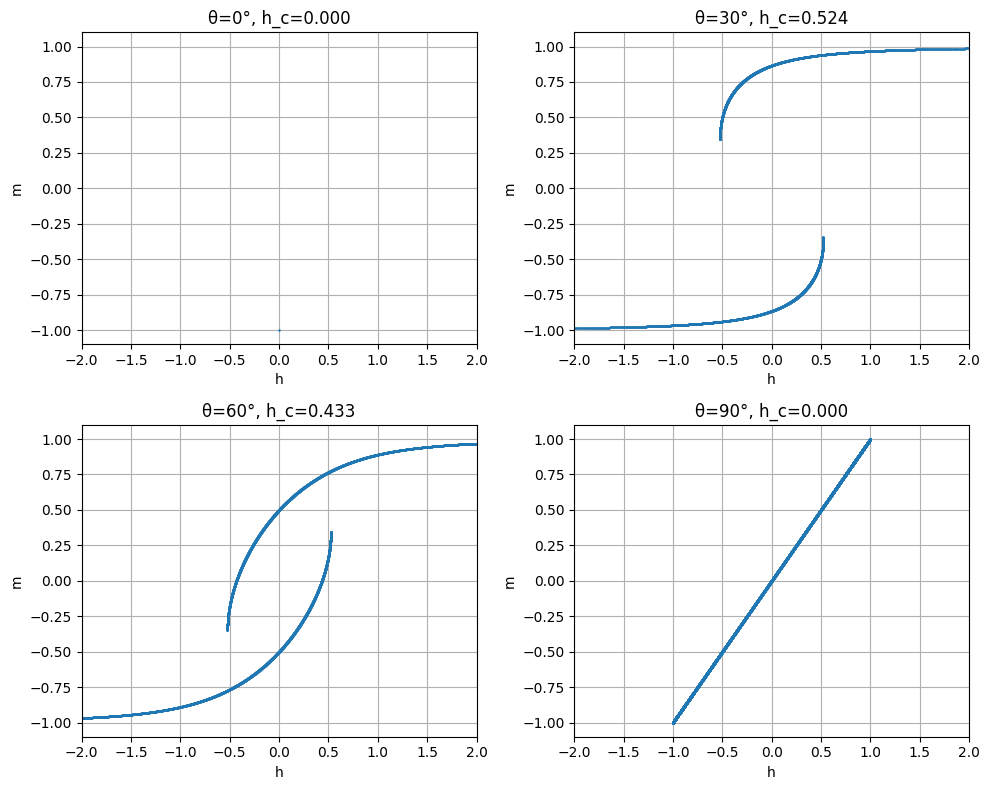

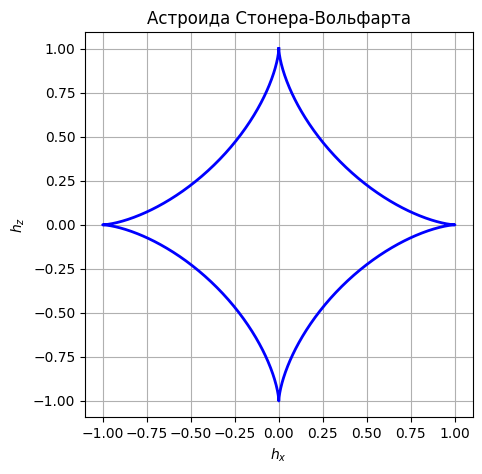

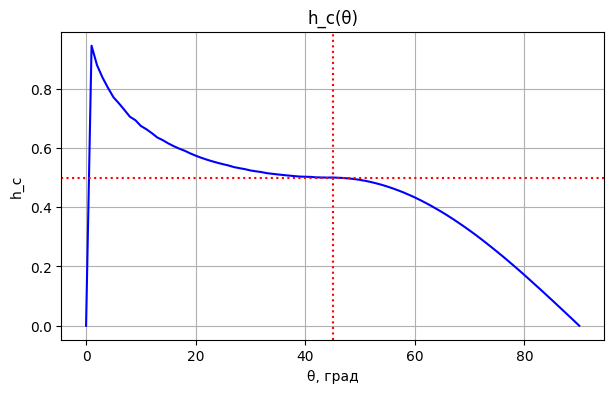


№3. АНАЛИЗ РЕЗУЛЬТАТОВ
-------------------------------------------------------
3.1) Число устойчивых минимумов:
   h=-1.0:  θ=90° -> 1,  θ=0° -> 0
   h=-0.5:  θ=90° -> 2,  θ=0° -> 1
   h=+0.0:  θ=90° -> 1,  θ=0° -> 1
   h=+0.5:  θ=90° -> 2,  θ=0° -> 1
   h=+1.0:  θ=90° -> 1,  θ=0° -> 1

3.2) Сравнение h_c(45°) с теорией:
численно: 0.5006
теоретически: 0.5000
ошибка: 0.12 %


In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

os.makedirs("figures", exist_ok=True)

phi, h, theta = sp.symbols('ϕ h θ', real=True)
hx, hz = sp.symbols('hx hz', real=True)

print("\n№1. ТЕОРЕТИЧЕСКИЙ РАСЧЁТ")
print("-" * 55)

e = sp.sin(phi)**2/2 - h*sp.cos(theta - phi)
print("\n1) e(ϕ), исходное:", e)
for d in [0, 45, 90]:
    print(f"θ={d:>2}°: e =", sp.simplify(e.subs(theta, sp.rad(d))))

print("\n2) Производные:")
print("de/dϕ) =", sp.diff(e, phi))
print("d2e/dϕ)2 =", sp.diff(e, phi, 2))

e2 = sp.sin(phi)**2/2 - hz*sp.cos(phi) - hx*sp.sin(phi)
sol = sp.solve([sp.diff(e2, phi), sp.diff(e2, phi, 2)], [hx, hz], dict=True)[0]
hxs, hzs = sp.simplify(sol[hx]), sp.simplify(sol[hz])
print("\n3) Решение системы:")
print("hx =", hxs)
print("hz =", hzs)
print("|hx|^(2/3)+|hz|^(2/3) =", sp.simplify(sp.Abs(hxs)**sp.Rational(2, 3) + sp.Abs(hzs)**sp.Rational(2, 3)))

hc_form = 1 / (sp.Abs(sp.sin(theta))**sp.Rational(2, 3) + sp.Abs(sp.cos(theta))**sp.Rational(2, 3))**sp.Rational(3, 2)
print("\n4) h_crit(θ) =", hc_form)
for d in [0, 45, 90]:
    print(f"h_crit({d:>2}°) =", hc_form.subs(theta, sp.rad(d)).evalf(4))


def loop(th_deg, N=20000):
    th = np.deg2rad(th_deg)
    ph = np.linspace(-np.pi, np.pi, N)

    den = 2*np.sin(th - ph)
    den[np.abs(den) < 1e-12] = 1e-12
    hh = np.sin(2*ph) / den

    m = np.cos(th - ph)
    d2 = np.cos(2*ph) + hh*np.cos(th - ph)

    ok = (d2 > 0) & (np.abs(hh) <= 2)
    return hh[ok], m[ok]


def hc(th_deg):
    hh, m = loop(th_deg)
    i = np.argsort(hh)
    hh, m = hh[i], m[i]
    sign = np.where(np.diff(np.sign(m)))[0]
    if len(sign) == 0:
        return 0.0
    return float(np.max(np.abs(hh[sign])))


print("\n№2. РАСЧЁТНОЕ МОДЕЛИРОВАНИЕ")
print("-" * 55)

plt.figure(figsize=(10, 8))
for k, a in enumerate([0, 30, 60, 90], 1):
    hh, m = loop(a)
    plt.subplot(2, 2, k)
    plt.plot(hh, m, '.', ms=1)
    plt.title(f"θ={a}°, h_c={hc(a):.3f}")
    plt.xlabel('h'); plt.ylabel('m')
    plt.xlim(-2, 2); plt.ylim(-1.1, 1.1)
    plt.grid()
plt.tight_layout()
plt.savefig('figures/hysteresis.png', dpi=150)
plt.show()

t = np.linspace(0, 2*np.pi, 1000)
plt.figure(figsize=(5, 5))
plt.plot(-np.sin(t)**3, np.cos(t)**3, 'b', lw=2)
plt.title('Астроида Стонера-Вольфарта')
plt.xlabel('$h_x$'); plt.ylabel('$h_z$')
plt.grid(); plt.axis('equal')
plt.savefig('figures/astroid.png', dpi=150)
plt.show()

th = np.linspace(0, 90, 91)
plt.figure(figsize=(7, 4))
plt.plot(th, [hc(x) for x in th], 'b')
plt.axhline(0.5, color='r', ls=':')
plt.axvline(45, color='r', ls=':')
plt.title('h_c(θ)')
plt.xlabel('θ, град'); plt.ylabel('h_c')
plt.grid()
plt.savefig('figures/coercivity.png', dpi=150)
plt.show()

def d2e(phi, h, theta):
    return np.cos(2*phi) + h*np.cos(theta - phi)

def n_min(th_deg, h):
    th = np.deg2rad(th_deg)
    ph = np.linspace(-np.pi, np.pi, 5000)
    d1 = 0.5*np.sin(2*ph) - h*np.sin(th - ph)
    idx = np.where(np.diff(np.sign(d1)) > 0)[0]
    return sum(1 for i in idx if d2e(ph[i], h, th) > 0)


print("\n№3. АНАЛИЗ РЕЗУЛЬТАТОВ")
print("-" * 55)

print("3.1) Число устойчивых минимумов:")
for h0 in [-1.0, -0.5, 0.0, 0.5, 1.0]:
    print(f"   h={h0:+.1f}:  θ=90° -> {n_min(90, h0)},  "
          f"θ=0° -> {n_min(0, h0)}")

print("\n3.2) Сравнение h_c(45°) с теорией:")
num, theor = hc(45), 0.5
err = abs(num - theor)/theor*100
print(f"численно: {num:.4f}")
print(f"теоретически: {theor:.4f}")
print(f"ошибка: {err:.2f} %")